# p53 / Mdm2 response to DNA damage

This notebook reproduces the analysis of the p53 / Mdm2 model of the [MaBoSS website](https://maboss.curie.fr).

The model is based on a published model of the p53 response to DNA damage
([Abou-Jaoudé et al., 2009](https://doi.org/10.1016/j.jtbi.2009.02.017)). p53 interacts with Mdm2, which appears
in two forms, cytoplasmic (Mdm2C) and nuclear (Mdm2N). On one hand, p53 upregulates the level of cytoplasmic
Mdm2, which is then transported into the nucleus. On the other hand, nuclear Mdm2 facilitates the degradation
of p53. DNA damage (Dam) participates in the degradation of Mdm2, and p53 inhibits the DNA damage signal by
promoting DNA repair.

p53 has three levels (0, 1 and 2), encoded with two Boolean nodes: `p53` is active when the level of p53 is at
least 1, and `p53_h` when it is 2.

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/), and the files `p53_Mdm2.bnd` and
`p53_Mdm2_runcfg.cfg`, in the same folder as this notebook.

In [1]:
import os
import maboss
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

# Common style for the figures of the MaBoSS website notebooks
COLORS = ["#FF7F00", "#1F77B4", "#2CA02C", "#D62728", "#9467BD",
          "#8C564B", "#E377C2", "#17BECF", "#BCBD22", "#7F7F7F"]
mpl.rcParams.update({
    "figure.figsize": (7, 4),
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "axes.prop_cycle": mpl.cycler(color=COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "legend.frameon": False,
    "lines.linewidth": 2,
})

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    """Save a figure in the figures folder."""
    fig.savefig(os.path.join(FIG_DIR, name + ".png"))

def state_label(state):
    """Readable label for a MaBoSS state."""
    return "none active" if state == "<nil>" else state.replace(" -- ", ", ")

def pie(probas, ax, title=None, min_proba=0.01, labels=None):
    """Pie chart of a distribution; probabilities below min_proba are grouped as 'others'."""
    probas = pd.Series(probas).sort_values(ascending=False)
    small = probas[probas < min_proba]
    probas = probas[probas >= min_proba]
    if len(small) > 0:
        probas["others"] = small.sum()
    names = [labels.get(s, state_label(s)) if labels else state_label(s) for s in probas.index]
    colors = [COLORS[i % len(COLORS)] if s != "others" else "#D9D9D9" for i, s in enumerate(probas.index)]
    wedges, _ = ax.pie(probas.values, colors=colors, startangle=90, counterclock=False,
                       wedgeprops={"linewidth": 1, "edgecolor": "white"})
    ax.legend(wedges, [f"{n} ({p:.1%})" for n, p in zip(names, probas.values)],
              loc="center left", bbox_to_anchor=(1, 0.5))
    ax.set_aspect("equal")
    if title:
        ax.set_title(title)

def set_refstate_all(sim, value=0):
    """Give a reference state to every node.

    With MaBoSS 2.6.6, the states of the stationary distributions only include the nodes
    having a reference state; this makes them include all the nodes, as in previous versions.
    """
    for node in sim.network:
        if node not in sim.refstate:
            sim.refstate[node] = value

ipylab module is not installed, menus and toolbar are disabled.


## Simulation

The initial condition is [p53 Mdm2C Mdm2N Dam] = [0 \* 1 1]: DNA damage is present, nuclear Mdm2 is active,
and p53 is inactive.

In [2]:
sim = maboss.load("p53_Mdm2.bnd", "p53_Mdm2_runcfg.cfg")
result = sim.run()

## Levels of p53

We compute the probabilities of each level of p53 from the probabilities of the network states.

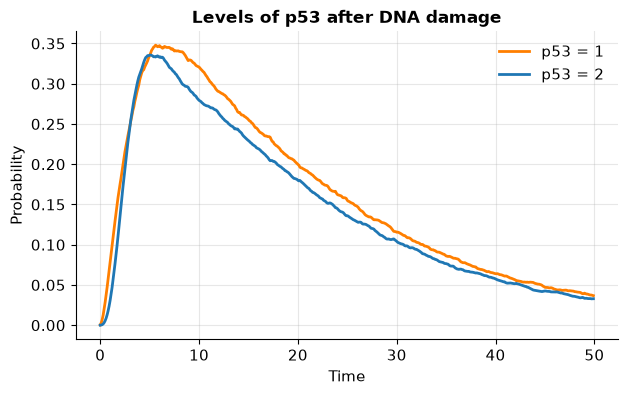

In [3]:
states = result.get_states_probtraj()

def active_nodes(state):
    return set() if state == "<nil>" else set(state.split(" -- "))

level_1 = [s for s in states.columns if "p53" in active_nodes(s) and "p53_h" not in active_nodes(s)]
level_2 = [s for s in states.columns if "p53_h" in active_nodes(s)]

fig, ax = plt.subplots()
ax.plot(states.index, states[level_1].sum(axis=1), label="p53 = 1")
ax.plot(states.index, states[level_2].sum(axis=1), label="p53 = 2")
ax.set_xlabel("Time")
ax.set_ylabel("Probability")
ax.set_title("Levels of p53 after DNA damage")
ax.legend()
save(fig, "p53_levels")

## Entropies

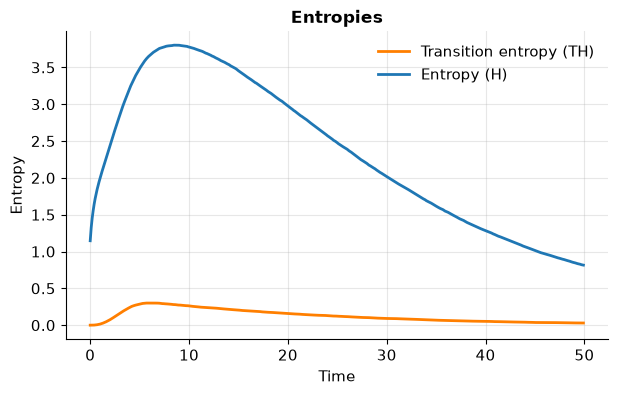

In [4]:
entropy = result.get_entropy_trajectory()

fig, ax = plt.subplots()
ax.plot(entropy.index, entropy["TH"], label="Transition entropy (TH)")
ax.plot(entropy.index, entropy["H"], label="Entropy (H)")
ax.set_xlabel("Time")
ax.set_ylabel("Entropy")
ax.set_title("Entropies")
ax.legend()
save(fig, "p53_entropies")